# NOAA AIS — XÁC MINH SỐ LIỆU & VIẾT MỤC 6.5–6.6 (V2)

**Đầu vào duy nhất: noaa_ais_2025_raw_labeled.parquet.** Không đọc bản sạch hoặc preprocessed.

## Cách chạy trên Kaggle
1. Import notebook, thêm dataset đã dùng; CPU, Run All.
2. Mặc định quét toàn bộ raw hai lượt: lượt 1 EDA/mẫu, lượt 2 kiểm chứng bộ lọc và số tàu/chuyến. Dữ liệu xử lý theo batch, không giữ 320 triệu dòng trong RAM.
3. Thực nghiệm mô hình/điền khuyết dùng mẫu 320.000 dòng; không gọi các kết quả này là huấn luyện toàn bộ dữ liệu.
4. Kết quả tách trong RAW2, TASK03, AUDIT và REPORTS. Cuối notebook tạo ZIP. Mở `REPORTS/Muc_6_5_6_6.md` để lấy nội dung chèn Docs.
5. Cache chỉ tái sử dụng khi cùng input/config. Dùng thư mục V2 riêng để tránh lẫn output cũ.

## Sửa đổi quan trọng so với V1
- Asymmetric loss phạt **e = dự báo − thực tế < 0**, đúng chiều dự báo sớm trong PDF. α=1,5 tương ứng trọng số 2,5. Mọi cấu hình đánh giá cùng chi phí nghiệp vụ phạt sớm 2,5 lần.
- Tách rõ số liệu full raw, full raw sau các bộ lọc có thể tái hiện, mẫu sau lọc và validation.
- Xuất đối chiếu số liệu cũ với trạng thái xác minh, không ép kết quả mới trùng số cũ.
- Tạo lại bảng mask-and-recover: thử nghiệm theo thời gian và thêm thử nghiệm che theo tàu, 20 lần trên mẫu. Không giả vờ tái hiện 11.006 tàu đầy đủ.
- Tạo bản nháp 6.5–6.6 bằng số liệu mới và nhận xét điều kiện theo kết quả.

## Không thể xác minh chỉ bằng raw labeled
Không có `atd_prev`, catalog gốc, log Pass 1/Pass 2 hoặc cấu hình chính xác pipeline cũ. Do đó không thể xác nhận số sự kiện catalog gốc, đúng số dòng sạch 80.782.630/80.660.588, peak RAM/đĩa của pipeline cũ hoặc baseline Ridge Q4 cũ. Đếm chuyến đã ghép trong raw không đồng nghĩa đếm toàn bộ catalog.

Khử trùng lặp toàn cục là kiểm tra tùy chọn dùng DuckDB và đĩa tạm; mặc định tắt vì có thể tốn nhiều thời gian/đĩa. Báo cáo luôn ghi trạng thái thực hiện. Không có bộ lọc atd_prev hoặc dedup trong waterfall mặc định.

Các số liệu cũ chỉ là giá trị tham chiếu từ tài liệu, không là expected assertion. Không có yêu cầu mọi số mới phải trùng số cũ.


In [1]:
from pathlib import Path
import json, gc, time, zipfile, importlib.util, platform
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink

required_packages = ['pyarrow', 'lightgbm']
missing_packages = [p for p in required_packages if importlib.util.find_spec(p) is None]
if missing_packages:
    raise ImportError('Môi trường thiếu package: ' + ', '.join(missing_packages)
                      + '. Hãy cài vào môi trường rồi chạy lại. Notebook không tự dùng Internet.')
import pyarrow.parquet as pq
import lightgbm as lgb

ROOT = Path('/kaggle/input/noaa-ais-2025-full-year-tin-x-l-nn-tng')
OUT = Path('/kaggle/working/task03_raw02_v2')
BATCH_SIZE = 250_000
SAMPLE_SIZE = 320_000
SEED = 42
MAX_BATCHES = None       # None = toàn bộ; đặt 10 để chạy thử, KHÔNG báo cáo là toàn năm
REUSE_SCAN_CACHE = True  # Cache chỉ dùng khi input/config khớp và scan trước hoàn tất
KNOWN_DESTINATION_AT_PREDICTION = False
RUN_ASYMMETRIC_EXPERIMENT = True
N_ESTIMATORS = 2000
N_JOBS = 4

OUT.mkdir(parents=True, exist_ok=True)
RAW2 = OUT / 'RAW2'
TASK03 = OUT / 'TASK03'
COMMON = OUT / 'COMMON'
for folder in [RAW2, TASK03, COMMON]: folder.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('Python:', platform.python_version(), '| LightGBM:', lgb.__version__)

AUDIT=OUT/'AUDIT'; REPORTS=OUT/'REPORTS'
AUDIT.mkdir(exist_ok=True); REPORTS.mkdir(exist_ok=True)
RUN_FULL_AUDIT=True
RUN_EXACT_DUPLICATE_AUDIT=False # tùy chọn: cần DuckDB, thời gian và đĩa tạm
DUPLICATE_MEMORY_LIMIT='2GB'
DUPLICATE_DISK_LIMIT='8GB'
MASK_REPEATS=20


Python: 3.13.15 | LightGBM: 4.6.0


In [2]:
raw_path = ROOT / 'noaa_ais_2025_raw_labeled.parquet'
if not raw_path.exists():
    matches = list(ROOT.rglob('noaa_ais_2025_raw_labeled.parquet')) if ROOT.exists() else []
    if not matches:
        matches = list(Path('/kaggle/input').rglob('noaa_ais_2025_raw_labeled.parquet'))
    if len(matches) != 1:
        raise FileNotFoundError(f'Cần đúng một raw labeled. Tìm thấy: {matches}. Sửa ROOT.')
    raw_path = matches[0]
assert raw_path.name == 'noaa_ais_2025_raw_labeled.parquet'
pf = pq.ParquetFile(raw_path)
COLS = ['mmsi','trip_id','base_date_time','longitude','latitude','sog','cog',
        'heading','status','vessel_type','length','width','draft','cargo',
        'berth_lon','berth_lat','ata_time','Target_Hours']
assert set(COLS).issubset(pf.schema_arrow.names), 'Schema raw thiếu cột yêu cầu'
print('Đầu vào duy nhất:', raw_path)
print('Số dòng metadata:', f'{pf.metadata.num_rows:,}')
print(pf.schema_arrow)
(COMMON / 'schema.txt').write_text(str(pf.schema_arrow), encoding='utf-8')

def save_table(df, path):
    df.to_csv(path, index=False, encoding='utf-8-sig')

def save_fig(fig, path):
    fig.tight_layout()
    fig.savefig(path, dpi=220, bbox_inches='tight')
    plt.show()
    plt.close(fig)


Đầu vào duy nhất: /kaggle/input/datasets/kienvo134/noaa-ais-2025-full-year-tin-x-l-nn-tng/noaa_ais_2025_raw_labeled.parquet
Số dòng metadata: 320,776,922
mmsi: int64
trip_id: string
base_date_time: timestamp[us]
longitude: float
latitude: float
sog: float
cog: float
heading: float
status: float
vessel_type: float
length: float
width: float
draft: float
cargo: float
berth_lon: float
berth_lat: float
ata_time: timestamp[us]
Target_Hours: float


# A. TASK-RAW-02 — Mục 5.4 và 6.1–6.4
## A1. Quét raw theo batch, EDA toàn bộ và lấy mẫu đều
Lấy mẫu bằng vị trí dòng chọn ngẫu nhiên không hoàn lại, không cân bằng lại target. RAM chỉ chứa một batch và mẫu nhỏ. Cache chỉ được đánh dấu hoàn tất sau khi scan xong; nếu kernel bị dừng giữa scan, chạy lại từ đầu.

`N` thống kê chỉ gồm giá trị hữu hạn; NaN/±Inf được đếm riêng. Std dùng mẫu (`ddof=1`). Các histogram có đếm ngoài miền trong bảng audit. Khi chạy thử giới hạn batch, mẫu chỉ đại diện phần đã quét.


In [3]:
scan_config = dict(path=str(raw_path), file_size=raw_path.stat().st_size,
                   mtime_ns=raw_path.stat().st_mtime_ns, rows=pf.metadata.num_rows,
                   batch_size=BATCH_SIZE, sample_size=SAMPLE_SIZE, seed=SEED,
                   max_batches=MAX_BATCHES, version=2)
cache_meta = COMMON / 'scan_complete.json'
cache_files = ['raw_sample.parquet','audit.csv','moments.csv','vessel.csv','status.csv','histograms.npz']
use_cache = (REUSE_SCAN_CACHE and cache_meta.exists()
             and all((COMMON / p).exists() for p in cache_files)
             and json.loads(cache_meta.read_text()) == scan_config)

sog_edges = np.linspace(0, 110, 221)
y_edges = np.linspace(0, 168, 85)
stat_cols = ['Target_Hours','sog','cog','draft','length','width']

def num(d, c):
    return pd.to_numeric(d[c], errors='coerce').to_numpy(dtype=float, na_value=np.nan)

if use_cache:
    sample = pd.read_parquet(COMMON / 'raw_sample.parquet')
    audit = pd.read_csv(COMMON / 'audit.csv')
    moments = pd.read_csv(COMMON / 'moments.csv')
    vessel_table = pd.read_csv(COMMON / 'vessel.csv', dtype={'value':str})
    status_table = pd.read_csv(COMMON / 'status.csv', dtype={'value':str})
    h = np.load(COMMON / 'histograms.npz')
    hist_sog, hist_target = h['sog'], h['target']
    print('Đã dùng cache hoàn tất với config khớp.')
else:
    cache_meta.unlink(missing_ok=True)
    rng = np.random.default_rng(SEED)
    total = pf.metadata.num_rows
    positions = np.sort(rng.choice(total, size=min(SAMPLE_SIZE,total), replace=False))
    counts, vessels, statuses = Counter(), Counter(), Counter()
    states = {c:dict(n=0, mean=0., m2=0., min=np.inf, max=-np.inf) for c in stat_cols}
    hist_sog = np.zeros(len(sog_edges)-1, dtype=np.int64)
    hist_target = np.zeros(len(y_edges)-1, dtype=np.int64)
    parts, offset, started = [], 0, time.time()
    for i, batch in enumerate(pf.iter_batches(batch_size=BATCH_SIZE, columns=COLS)):
        if MAX_BATCHES is not None and i >= MAX_BATCHES: break
        d = batch.to_pandas()
        n = len(d)
        counts['N_raw'] += n
        for c in stat_cols:
            x = num(d,c); x = x[np.isfinite(x)]
            if len(x):
                st = states[c]; bn=len(x); bm=float(x.mean()); bm2=float(((x-bm)**2).sum())
                delta=bm-st['mean']; nn=st['n']+bn
                st['m2'] += bm2 + delta*delta*st['n']*bn/nn
                st['mean'] += delta*bn/nn
                st['n']=nn; st['min']=min(st['min'],float(x.min())); st['max']=max(st['max'],float(x.max()))
        s = num(d,'sog'); fs=np.isfinite(s)
        groups = {'SOG_nonfinite':~fs,'SOG_negative':fs&(s<0),'SOG_zero':fs&(s==0),
                  'SOG_0_to_1':fs&(s>0)&(s<1),'SOG_1_to_40':fs&(s>=1)&(s<=40),
                  'SOG_over_40':fs&(s>40),'SOG_over_110':fs&(s>110)}
        y=num(d,'Target_Hours'); fy=np.isfinite(y)
        groups.update({'Target_nonfinite':~fy,'Target_negative':fy&(y<0),
                       'Target_zero':fy&(y==0),'Target_0_to_168':fy&(y>0)&(y<=168),
                       'Target_over_168':fy&(y>168)})
        for c in ['length','width','draft']:
            x=num(d,c); f=np.isfinite(x)
            groups[c+'_nonfinite']=~f
            groups[c+'_invalid_finite']=f&((x<=0)|((x>25.5) if c=='draft' else False))
        for k,v in groups.items(): counts[k] += int(v.sum())
        hist_sog += np.histogram(s[fs],bins=sog_edges)[0]
        hist_target += np.histogram(y[fy&(y>=0)&(y<=168)],bins=y_edges)[0]
        for c, counter in [('vessel_type',vessels),('status',statuses)]:
            v=pd.to_numeric(d[c],errors='coerce'); v=v.where(np.isfinite(v))
            labels=v.astype('string').fillna('Missing')
            counter.update(labels.value_counts().to_dict())
        lo=np.searchsorted(positions,offset); hi=np.searchsorted(positions,offset+n)
        if hi>lo: parts.append(d.iloc[positions[lo:hi]-offset].copy())
        offset += n
        if (i+1)%50==0: print(f'Batch {i+1:,} | {offset:,} dòng | {(time.time()-started)/60:.1f} phút')
        del d,batch
    if not parts: raise ValueError('Không có mẫu; tăng MAX_BATCHES hoặc SAMPLE_SIZE.')
    sample=pd.concat(parts,ignore_index=True); del parts
    if MAX_BATCHES is None: assert offset==total
    audit=pd.DataFrame([{'metric':k,'count':int(v)} for k,v in counts.items()])
    audit['pct_of_scanned_raw']=100*audit['count']/offset
    moments=pd.DataFrame([dict(variable=c,N=st['n'],Mean=st['mean'] if st['n'] else np.nan,
               Std=np.sqrt(st['m2']/(st['n']-1)) if st['n']>1 else np.nan,
               Min=st['min'] if st['n'] else np.nan,Max=st['max'] if st['n'] else np.nan)
               for c,st in states.items()])
    def tab(counter):
        t=pd.DataFrame(list(counter.items()),columns=['value','count']).sort_values('count',ascending=False)
        t['pct_of_scanned_raw']=100*t['count']/offset
        return t
    vessel_table,status_table=tab(vessels),tab(statuses)
    sample.to_parquet(COMMON/'raw_sample.parquet',index=False)
    for df,name in [(audit,'audit.csv'),(moments,'moments.csv'),(vessel_table,'vessel.csv'),(status_table,'status.csv')]:
        save_table(df,COMMON/name)
    np.savez(COMMON/'histograms.npz',sog=hist_sog,target=hist_target)
    cache_meta.write_text(json.dumps(scan_config,ensure_ascii=False,indent=2))
    gc.collect()
SCOPE = 'Toàn bộ raw' if MAX_BATCHES is None else 'CHẠY THỬ: phần raw đã quét'
print(SCOPE, '| Mẫu:',len(sample))
display(audit)
display(moments)


Batch 50 | 12,500,000 dòng | 0.4 phút
Batch 100 | 25,000,000 dòng | 0.9 phút
Batch 150 | 37,500,000 dòng | 1.3 phút
Batch 200 | 50,000,000 dòng | 1.7 phút
Batch 250 | 62,500,000 dòng | 2.1 phút
Batch 300 | 75,000,000 dòng | 2.5 phút
Batch 350 | 87,500,000 dòng | 3.0 phút
Batch 400 | 100,000,000 dòng | 3.4 phút
Batch 450 | 112,500,000 dòng | 3.8 phút
Batch 500 | 125,000,000 dòng | 4.2 phút
Batch 550 | 137,500,000 dòng | 4.6 phút
Batch 600 | 150,000,000 dòng | 5.0 phút
Batch 650 | 162,500,000 dòng | 5.5 phút
Batch 700 | 175,000,000 dòng | 5.9 phút
Batch 750 | 187,500,000 dòng | 6.3 phút
Batch 800 | 200,000,000 dòng | 6.7 phút
Batch 850 | 212,500,000 dòng | 7.2 phút
Batch 900 | 225,000,000 dòng | 7.6 phút
Batch 950 | 237,500,000 dòng | 8.0 phút
Batch 1,000 | 250,000,000 dòng | 8.4 phút
Batch 1,050 | 262,500,000 dòng | 8.9 phút
Batch 1,100 | 275,000,000 dòng | 9.3 phút
Batch 1,150 | 287,500,000 dòng | 9.7 phút
Batch 1,200 | 300,000,000 dòng | 10.1 phút
Batch 1,250 | 312,500,000 dòng | 10.6

,metric,count,pct_of_scanned_raw
0,N_raw,320776922,100.000000
1,SOG_nonfinite,299345,0.093319
2,SOG_negative,0,0.000000
3,SOG_zero,119366838,37.211791
4,SOG_0_to_1,37236779,11.608310
5,SOG_1_to_40,163873321,51.086381
6,SOG_over_40,639,0.000199
7,SOG_over_110,0,0.000000
8,Target_nonfinite,38453008,11.987461
9,Target_negative,0,0.000000


,variable,N,Mean,Std,Min,Max
0,Target_Hours,282323914,436.590556,887.360077,0.0,8723.911133
1,sog,320477577,5.691375,6.244542,0.0,99.900002
2,cog,317652172,185.409956,103.424948,0.0,359.899994
3,draft,312893244,8.616703,2.904418,0.1,24.299999
4,length,319269108,197.441388,75.355847,1.0,419.000000
5,width,316826290,30.696792,10.141872,2.0,61.000000


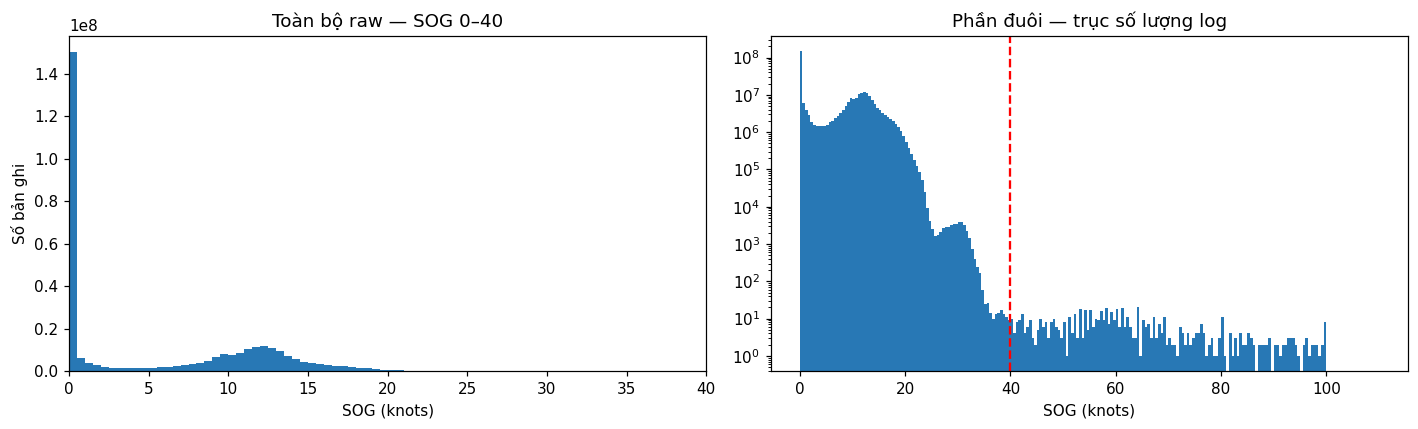

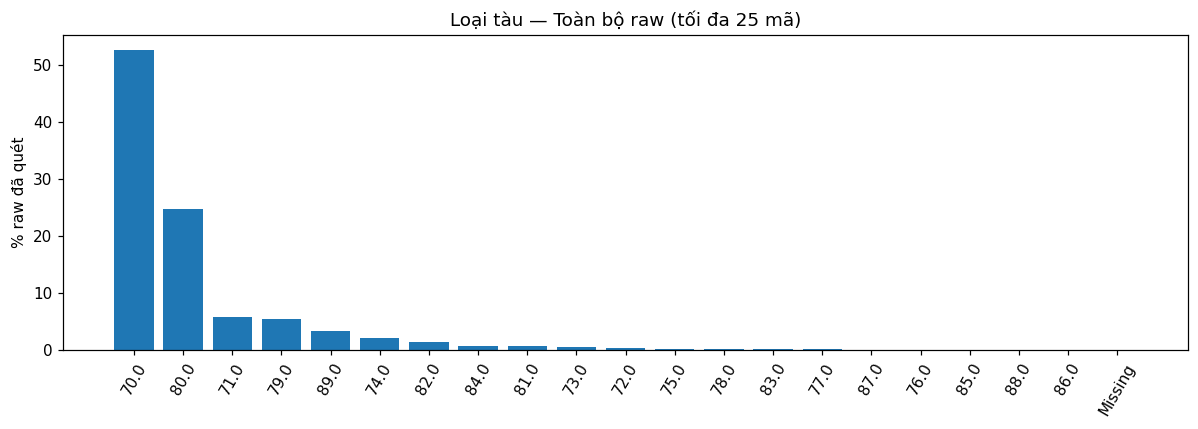

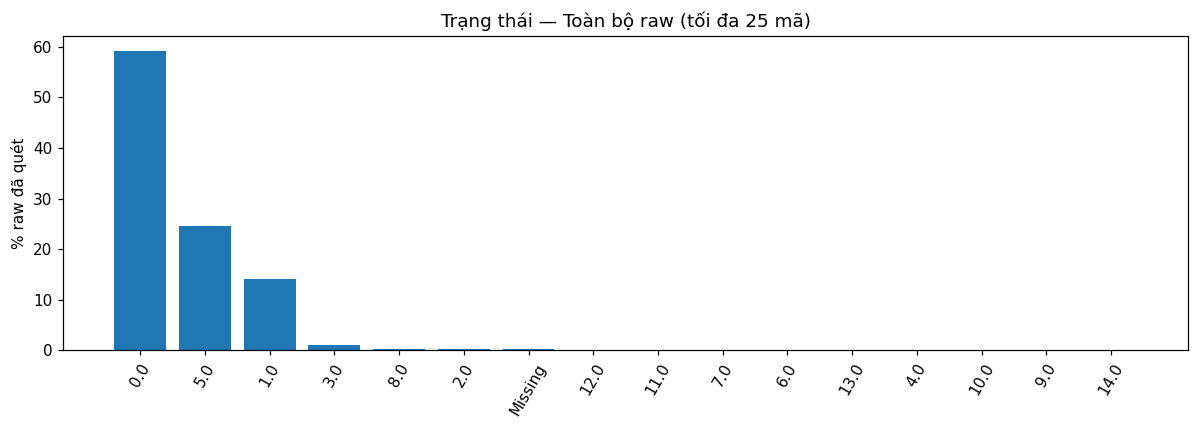

In [4]:
fig,axs=plt.subplots(1,2,figsize=(13,4))
for ax in axs: ax.stairs(hist_sog,sog_edges,fill=True,color='#2878B5'); ax.set_xlabel('SOG (knots)')
axs[0].set_xlim(0,40); axs[0].set_ylabel('Số bản ghi'); axs[0].set_title(SCOPE+' — SOG 0–40')
axs[1].set_yscale('log'); axs[1].axvline(40,color='red',ls='--'); axs[1].set_title('Phần đuôi — trục số lượng log')
save_fig(fig,RAW2/'01_sog.png')
for table,name,title in [(vessel_table,'02_vessel','Loại tàu'),(status_table,'03_status','Trạng thái')]:
    p=table.head(25)
    fig,ax=plt.subplots(figsize=(11,4)); ax.bar(p['value'].astype(str),p['pct_of_scanned_raw'])
    ax.tick_params(axis='x',rotation=60); ax.set_ylabel('% raw đã quét')
    ax.set_title(title+' — '+SCOPE+' (tối đa 25 mã)')
    save_fig(fig,RAW2/(name+'.png'))
# Sao chép các bảng đã tính; không đọc thêm dataset khác.
for df,name in [(audit,'raw_audit.csv'),(vessel_table,'vessel_types.csv'),(status_table,'status.csv')]:
    save_table(df,RAW2/name)


## A2. Mục 6.1 — mô tả nguồn gốc hai lượt
Pass 1 tạo catalog sự kiện cập bến; ghép nhãn tạo raw labeled. Notebook bắt đầu **sau** các bước này. Không kiểm chứng lại 102.050 sự kiện hoặc số dòng sạch trong tài liệu.

## A3. Mục 6.2/6.4 — tạo biến và bộ lọc trên mẫu
Haversine với bán kính phụ thuộc vĩ độ là xấp xỉ đại vòng, không phải geodesic ellipsoid chính xác. KM/NM là cùng thông tin tuyến tính (dự án đã chuẩn hóa giữ duy nhất Dist_To_Berth_NM). Area/Volume là proxy kích thước, không phải phép đo chính xác cản gió/chiếm nước.

Waterfall chưa khử trùng lặp toàn cục, chưa lọc `atd_prev`. Lọc vận tốc biểu kiến dùng target nên chỉ là lựa chọn quần thể nghiên cứu ngoại tuyến; kết quả validation chỉ áp dụng quần thể đã chọn, không đại diện vận hành raw không chọn lọc.


In [ ]:
def engineer(raw):
    d=raw.copy()
    numeric=['longitude','latitude','berth_lon','berth_lat','sog','cog','heading',
             'status','vessel_type','length','width','draft','cargo','Target_Hours']
    for c in numeric:
        d[c]=pd.to_numeric(d[c],errors='coerce').astype(float)
        d[c]=d[c].where(np.isfinite(d[c]))
    for c in ['base_date_time','ata_time']: d[c]=pd.to_datetime(d[c],errors='coerce',utc=True)
    ok=(d.latitude.between(-90,90)&d.longitude.between(-180,180)
        &d.berth_lat.between(-90,90)&d.berth_lon.between(-180,180))
    p=d.loc[ok]; lat1=np.radians(p.latitude); lat2=np.radians(p.berth_lat)
    dl=(np.radians(p.berth_lon-p.longitude)+np.pi)%(2*np.pi)-np.pi
    h=np.sin((lat2-lat1)/2)**2+np.cos(lat1)*np.cos(lat2)*np.sin(dl/2)**2
    phi=(lat1+lat2)/2; a=6378.137; b=6356.752314245
    radius=np.sqrt(((a*a*np.cos(phi))**2+(b*b*np.sin(phi))**2)/((a*np.cos(phi))**2+(b*np.sin(phi))**2))
    d['Dist_To_Berth_NM']=np.nan
    d.loc[ok,'Dist_To_Berth_NM']=2*radius*np.arcsin(np.sqrt(np.clip(h,0,1)))/1.852
    d['Area_Proxy']=d.length*d.width; d['Volume_Proxy']=d.Area_Proxy*d.draft
    d['Is_Tanker']=np.where(d.vessel_type.between(70,89),d.vessel_type.between(80,89).astype(float),np.nan)
    for c in ['cog','heading']:
        angle=np.radians(d[c].where(d[c].ge(0)&d[c].lt(360)))
        d[c+'_sin']=np.sin(angle); d[c+'_cos']=np.cos(angle)
    return d

def filter_sample(d):
    y=d.Target_Hours; dist=d.Dist_To_Berth_NM
    max_dist_nm=np.where(d.Is_Tanker.eq(1),1800.0,2300.0)
    rules=[('SOG [1,40]',d.sog.between(1,40)),
           ('Status đủ dữ liệu, khác 1/5',d.status.notna()&~d.status.isin([1,5])),
           ('Vessel type nguyên [70,89]',d.vessel_type.between(70,89)&d.vessel_type.mod(1).eq(0)),
           ('BBox theo tài liệu',d.latitude.between(15,75)&d.longitude.between(-180,-65)),
           ('Target (0,168]',y.gt(0)&y.le(168)),
           ('Khoảng cách hợp lệ <=1800 NM (Tanker) / <=2300 NM (Cargo)',dist.notna()&dist.le(max_dist_nm)),
           ('Vận tốc biểu kiến >=1.62 knots',dist.div(y.where(y>0)).ge(1.62))]
    keep=pd.Series(True,index=d.index)
    rows=[dict(step='Mẫu raw',remaining=len(d),removed_this_step=0)]
    for name,mask in rules:
        before=int(keep.sum()); keep &= mask.fillna(False); after=int(keep.sum())
        rows.append(dict(step=name,remaining=after,removed_this_step=before-after))
    return d.loc[keep].copy(),pd.DataFrame(rows)

derived=engineer(sample)
work,waterfall=filter_sample(derived)
save_table(waterfall,RAW2/'sample_filter_waterfall.csv')
display(waterfall)
if work.empty: raise ValueError('Mẫu sau lọc rỗng. Kiểm tra schema/phạm vi hoặc tăng SAMPLE_SIZE.')


## A4. Mục 6.3 — điền khuyết và mask-and-recover
Ưu tiên RAW2: chuyến → tàu → loại tàu → nhóm Cargo/Tanker; thêm fallback trung vị toàn cục nếu cần. Không hard-code kích thước mẫu từ tài liệu.

Học lookup từ tháng 1–6 (nhãn đã hoàn tất trước 1/7), kiểm chứng tháng 7–9 (nhãn hoàn tất trước 1/10). Che ngẫu nhiên 20% giá trị vốn hợp lệ, so với trung vị toàn cục. Đây là thử nghiệm thiếu ngẫu nhiên, không đại diện mọi cơ chế thiếu thực tế. Lookup chuyến có thể không áp dụng được khi chuyến giữa hai tập không giao nhau; bảng nguồn sẽ thể hiện điều đó. Trong vận hành, lookup theo chuyến/tàu chỉ dùng dữ liệu quá khứ.


## A3b. Kiểm chứng toàn bộ raw: không suy rộng từ mẫu
Quét thêm một lượt theo batch; đếm chính xác các bộ lọc độc lập với batch. Đếm tàu, ID chuyến đã ghép và cặp (mmsi,trip_id); các định nghĩa không được đánh đồng.
Tính thiếu thân vỏ sau lọc, số tàu chưa từng có giá trị hợp lệ trên raw đã quét và Pearson khoảng cách–target trên raw/sau lọc. Cự ly được tạo lại từ raw. Waterfall **chưa dedup và chưa lọc atd_prev**.
Kiểm tra công thức nhãn dùng sai lệch >5 giây làm ngưỡng cảnh báo số học do float32; không chứng minh đúng sự kiện cập bến.


In [ ]:
full_results=None; full_waterfall=None; full_missing=None
if RUN_FULL_AUDIT:
    audit_config={**scan_config,'audit_version':1}
    flag=AUDIT/'full_audit_complete.json'
    needed=['full_summary.json','full_filter_waterfall.csv','full_filtered_missing.csv','vessel_body_availability.csv']
    reuse=(REUSE_SCAN_CACHE and flag.exists() and json.loads(flag.read_text())==audit_config
           and all((AUDIT/x).exists() for x in needed))
    if reuse:
        full_results=json.loads((AUDIT/'full_summary.json').read_text())
        full_waterfall=pd.read_csv(AUDIT/'full_filter_waterfall.csv')
        full_missing=pd.read_csv(AUDIT/'full_filtered_missing.csv')
    else:
        flag.unlink(missing_ok=True)
        raw_ships=set(); filtered_ships=set(); trips=set(); trip_pairs=set()
        missing_ids=Counter(); valid_body_ships={c:set() for c in ['length','width','draft']}
        body_count=Counter(); step_totals=None; scanned=0; mismatches=0; checked=0
        corr_states={name:dict(n=0,mx=0.,my=0.,xx=0.,yy=0.,xy=0.) for name in ['raw','filtered']}
        def update_corr(st,x,y):
            x=np.asarray(x,float); y=np.asarray(y,float); ok=np.isfinite(x)&np.isfinite(y); x=x[ok]; y=y[ok]
            n=len(x)
            if not n:return
            mx=x.mean();my=y.mean();dx=mx-st['mx'];dy=my-st['my'];total=st['n']+n;f=st['n']*n/total
            st['xx']+=float(((x-mx)**2).sum())+dx*dx*f
            st['yy']+=float(((y-my)**2).sum())+dy*dy*f
            st['xy']+=float(((x-mx)*(y-my)).sum())+dx*dy*f
            st['mx']+=dx*n/total; st['my']+=dy*n/total; st['n']=total
        started=time.time()
        for i,batch in enumerate(pf.iter_batches(batch_size=BATCH_SIZE,columns=COLS)):
            if MAX_BATCHES is not None and i>=MAX_BATCHES:break
            d=engineer(batch.to_pandas()); f,w=filter_sample(d); scanned+=len(d)
            if step_totals is None:step_totals=w.copy()
            else:step_totals[['remaining','removed_this_step']]+=w[['remaining','removed_this_step']]
            raw_ships.update(d.mmsi.dropna().tolist()); filtered_ships.update(f.mmsi.dropna().tolist())
            trips.update(d.trip_id.dropna().tolist())
            trip_pairs.update(d[['mmsi','trip_id']].dropna().drop_duplicates().itertuples(index=False,name=None))
            for c in ['mmsi','trip_id','ata_time','base_date_time']:missing_ids[c]+=int(d[c].isna().sum())
            expected=(d.ata_time-d.base_date_time).dt.total_seconds()/3600
            ok=expected.notna()&d.Target_Hours.notna();checked+=int(ok.sum())
            mismatches+=int(((expected[ok]-d.loc[ok,'Target_Hours']).abs()>5/3600).sum())
            for c in ['length','width','draft']:
                good=d[c].gt(0)&d[c].notna()
                if c=='draft':good &= d[c].le(25.5)
                valid_body_ships[c].update(d.loc[good,'mmsi'].dropna().tolist())
                bad=f[c].isna()|f[c].le(0)
                if c=='draft':bad |= f[c].gt(25.5)
                body_count[c+'_nonfinite']+=int(f[c].isna().sum())
                body_count[c+'_missing_or_invalid']+=int(bad.sum())
            body_count['Area_Proxy_nonfinite']+=int(f.Area_Proxy.isna().sum())
            body_count['Volume_Proxy_nonfinite']+=int(f.Volume_Proxy.isna().sum())
            update_corr(corr_states['raw'],d.Dist_To_Berth_NM,d.Target_Hours)
            update_corr(corr_states['filtered'],f.Dist_To_Berth_NM,f.Target_Hours)
            if (i+1)%50==0:print(f'Full audit: {scanned:,} dòng | {(time.time()-started)/60:.1f} phút')
            del d,f,batch
        if MAX_BATCHES is None:assert scanned==pf.metadata.num_rows
        def corr_value(st):
            return st['xy']/np.sqrt(st['xx']*st['yy']) if st['xx']>0 and st['yy']>0 else None
        final_n=int(step_totals.remaining.iloc[-1])
        full_results=dict(scope=SCOPE,scanned_rows=scanned,filtered_rows_no_dedup_no_atd=final_n,
             raw_unique_mmsi=len(raw_ships),filtered_unique_mmsi=len(filtered_ships),
             assigned_unique_trip_id=len(trips),assigned_unique_mmsi_trip=len(trip_pairs),
             missing_ids=dict(missing_ids),label_formula_checked=checked,label_formula_mismatch_over_5s=mismatches,
             raw_distance_target_pearson=corr_value(corr_states['raw']),
             filtered_distance_target_pearson=corr_value(corr_states['filtered']),
             raw_pairwise_n=corr_states['raw']['n'],filtered_pairwise_n=corr_states['filtered']['n'],
             input_bytes=raw_path.stat().st_size,metadata_row_groups=pf.num_row_groups)
        full_waterfall=step_totals
        full_missing=pd.DataFrame([dict(metric=k,count=int(v),denominator=final_n,
                                        pct=100*v/final_n if final_n else np.nan) for k,v in body_count.items()])
        vessel_availability=pd.DataFrame([dict(variable=c,raw_unique_mmsi=len(raw_ships),
                    vessels_never_valid=len(raw_ships-valid_body_ships[c]),
                    definition='Trên raw đã quét; thiếu hoặc <=0; draft thêm >25.5') for c in valid_body_ships])
        save_table(vessel_availability,AUDIT/'vessel_body_availability.csv')
        save_table(full_waterfall,AUDIT/'full_filter_waterfall.csv'); save_table(full_missing,AUDIT/'full_filtered_missing.csv')
        (AUDIT/'full_summary.json').write_text(json.dumps(full_results,ensure_ascii=False,indent=2),encoding='utf-8')
        flag.write_text(json.dumps(audit_config,ensure_ascii=False,indent=2),encoding='utf-8')
    display(full_waterfall); display(full_missing); print(json.dumps(full_results,ensure_ascii=False,indent=2))
else:
    print('Bỏ qua full audit; không xác minh được số dòng sau lọc toàn bộ.')


### Kiểm kê trùng lặp toàn cục (tùy chọn, không thay đổi mẫu/model)


In [7]:
duplicate_result={'status':'NOT_RUN','definition':'Số dòng dư theo (mmsi,base_date_time), trên khóa không null của toàn bộ raw'}
if RUN_EXACT_DUPLICATE_AUDIT:
    if MAX_BATCHES is not None:
        raise ValueError('Exact dedup quét toàn raw: đặt MAX_BATCHES=None để nhất quán phạm vi.')
    if importlib.util.find_spec('duckdb') is None:
        duplicate_result['status']='UNAVAILABLE_PACKAGE'
        print('Không có DuckDB; không thực hiện kiểm tra trùng lặp. Các phần khác vẫn chạy.')
    else:
        import duckdb
        con=duckdb.connect()
        temp=OUT/'duckdb_tmp';temp.mkdir(exist_ok=True)
        try:
            con.execute("SET memory_limit='"+DUPLICATE_MEMORY_LIMIT+"'")
            con.execute("SET max_temp_directory_size='"+DUPLICATE_DISK_LIMIT+"'")
            con.execute("SET temp_directory='"+str(temp).replace("'","''")+"'")
            con.execute('SET threads=2')
            result=con.execute("""SELECT SUM(n-1), COUNT(*), SUM(n) FROM
               (SELECT mmsi,base_date_time,COUNT(*) n FROM read_parquet(?)
                WHERE mmsi IS NOT NULL AND base_date_time IS NOT NULL
                GROUP BY mmsi,base_date_time)""",[str(raw_path)]).fetchone()
            duplicate_result.update(status='MEASURED',duplicate_excess=int(result[0] or 0),
                                    distinct_keys=int(result[1]),rows_with_valid_keys=int(result[2] or 0))
        except Exception as exc:
            duplicate_result.update(status='FAILED',error=str(exc))
            print('Kiểm tra trùng lặp không hoàn tất:',str(exc))
        finally: con.close()
(AUDIT/'duplicate_audit.json').write_text(json.dumps(duplicate_result,ensure_ascii=False,indent=2),encoding='utf-8')
print(duplicate_result)


{'status': 'NOT_RUN', 'definition': 'Số dòng dư theo (mmsi,base_date_time), trên khóa không null của toàn bộ raw'}


In [8]:
BODY=['length','width','draft']
LEVELS=[('trip',['mmsi','trip_id']),('vessel',['mmsi']),('type',['vessel_type']),('group',['_ship_group'])]
JAN=pd.Timestamp('2025-01-01',tz='UTC'); JUL=pd.Timestamp('2025-07-01',tz='UTC'); OCT=pd.Timestamp('2025-10-01',tz='UTC')

def prepare_body(df):
    d=df.copy()
    for c in BODY:
        ok=np.isfinite(d[c])&d[c].gt(0)
        if c=='draft': ok &= d[c].le(25.5)
        d[c]=d[c].where(ok)
    d['_ship_group']=pd.Series(pd.NA,index=d.index,dtype='string')
    d.loc[d.vessel_type.between(70,79),'_ship_group']='Cargo'
    d.loc[d.vessel_type.between(80,89),'_ship_group']='Tanker'
    return d

def fit_imputer(ref):
    ref=prepare_body(ref)
    return {c:{'global':ref[c].median(), 'maps':[(name,keys,ref.groupby(keys,dropna=True)[c].median())
            for name,keys in LEVELS]} for c in BODY}

def transform_imputer(data,lookup):
    d=prepare_body(data)
    for c in BODY:
        source=pd.Series('observed',index=d.index); source.loc[d[c].isna()]='unresolved'
        for name,keys,table in lookup[c]['maps']:
            if len(keys)==1: fill=d[keys[0]].map(table)
            else:
                idx=pd.MultiIndex.from_frame(d[keys]); fill=pd.Series(table.reindex(idx).to_numpy(),index=d.index)
            take=d[c].isna()&fill.notna(); d.loc[take,c]=fill.loc[take]; source.loc[take]=name
        take=d[c].isna()
        if pd.notna(lookup[c]['global']): d.loc[take,c]=lookup[c]['global']; source.loc[take]='global'
        d[c+'_source']=source
    d['Area_Proxy']=d.length*d.width; d['Volume_Proxy']=d.Area_Proxy*d.draft
    return d

train=work.loc[work.base_date_time.ge(JAN)&work.base_date_time.lt(JUL)&work.ata_time.lt(JUL)].copy()
valid=work.loc[work.base_date_time.ge(JUL)&work.base_date_time.lt(OCT)&work.ata_time.lt(OCT)].copy()
train=train.dropna(subset=['mmsi','trip_id']); valid=valid.dropna(subset=['mmsi','trip_id'])
tr_keys=pd.MultiIndex.from_frame(train[['mmsi','trip_id']]); va_keys=pd.MultiIndex.from_frame(valid[['mmsi','trip_id']])
train=train.loc[~tr_keys.isin(va_keys)].copy()
if len(train)<100 or len(valid)<100:
    raise ValueError('Không đủ mẫu train/validation. Dùng scan toàn năm và tăng SAMPLE_SIZE.')
print('Train:',len(train),'Validation:',len(valid),'| Q4 không sử dụng')
lookup=fit_imputer(train); truth=prepare_body(valid); masked=truth.copy()
rng=np.random.default_rng(SEED+1); masks={}
for c in BODY:
    eligible=truth.index[truth[c].notna()].to_numpy()
    masks[c]=rng.choice(eligible,size=max(1,int(.2*len(eligible))),replace=False) if len(eligible) else np.array([],dtype=int)
    masked.loc[masks[c],c]=np.nan
recovered=transform_imputer(masked,lookup)
rows=[]; sources=[]
for c in BODY:
    idx=masks[c]; actual=truth.loc[idx,c].to_numpy(float); pred=recovered.loc[idx,c].to_numpy(float)
    ok=np.isfinite(actual)&np.isfinite(pred); e=pred[ok]-actual[ok]
    rows.append(dict(variable=c,N_masked=len(idx),N_recovered=int(ok.sum()),
        coverage_pct=100*ok.mean() if len(ok) else np.nan,
        MAE=np.mean(abs(e)) if len(e) else np.nan,RMSE=np.sqrt(np.mean(e**2)) if len(e) else np.nan,
        global_median_MAE=np.mean(abs(actual-lookup[c]['global'])) if len(actual) else np.nan))
    for name,n in recovered.loc[idx,c+'_source'].value_counts().items():
        sources.append(dict(variable=c,source=name,count=int(n)))
mask_results=pd.DataFrame(rows); mask_sources=pd.DataFrame(sources)
save_table(mask_results,RAW2/'table_6_1_mask_recover.csv'); save_table(mask_sources,RAW2/'mask_recover_sources.csv')
display(mask_results); display(mask_sources)


Train: 39170 Validation: 21818 | Q4 không sử dụng


,variable,N_masked,N_recovered,coverage_pct,MAE,RMSE,global_median_MAE
0,length,4347,4347,100.0,7.090177,24.012501,52.102599
1,width,4307,4307,100.0,1.139772,3.819317,6.439749
2,draft,4343,4343,100.0,1.123601,1.662427,1.956413


,variable,source,count
0,length,vessel,3515
1,length,type,832
2,width,vessel,3435
3,width,type,872
4,draft,vessel,3484
5,draft,type,859


# B. TASK 03 — Mục 6.5 và 6.6
## B1. Target lệch phải
Moments tính trên raw đã quét, phân vị/skewness trên mẫu. Histogram log1p chỉ phục vụ hiển thị, không đổi target huấn luyện. Không dùng số Mean=41,24/Median=25,59 trong mẫu tài liệu để mô tả raw. Cửa sổ (0,168] là phạm vi lựa chọn, không phải đặc tính raw.

Không oversample/undersample để cân bằng target. Phân nhóm cự ly [0,50,200,500,∞) là ngưỡng thiết kế, giữ cố định trước khi xem Q4.


## A4b. Kiểm tra lại thiết kế che theo tàu: 20 lần trên mẫu
Không tái sử dụng bảng MAPE cũ. Mỗi tàu đại diện bằng median các giá trị hợp lệ trong mẫu sau lọc, loại tàu đại diện bằng mode. Chỉ xét tàu đủ ba kích thước. Mỗi lần giữ ngẫu nhiên 20% tàu để đánh giá và học lookup từ 80% tàu còn lại. Median theo mã chỉ áp dụng khi nhóm train có ít nhất 30 tàu; fallback nhóm Cargo/Tanker rồi toàn cục. Đánh giá Length/Width/Draft và hai proxy, báo MAPE mean/std qua 20 lần. Median trên tàu tránh tàu có nhiều bản tin chi phối **trong thử nghiệm này**.
Đây là kiểm chứng khái quát hóa sang tàu chưa thấy trong **mẫu**, không phải dự báo theo thời gian, không phải đúng đội tàu 11.006 của thí nghiệm cũ. Draft được tổng hợp theo tàu trong thí nghiệm che toàn tàu này, không được diễn giải là điền theo chuyến lúc vận hành. Giá trị quan sát là tham chiếu kiểm chứng, không phải đo kiểm thực địa.


In [9]:
body=prepare_body(work)
vessel_body=body.groupby('mmsi')[BODY].median().dropna()
def mode_one(s):
    mode=s.dropna().mode()
    return mode.iloc[0] if len(mode) else np.nan
vessel_body['vessel_type']=body.groupby('mmsi').vessel_type.agg(mode_one).reindex(vessel_body.index)
vessel_body=vessel_body.dropna(subset=['vessel_type'])
vessel_body['_ship_group']=np.where(vessel_body.vessel_type.ge(80),'Tanker','Cargo')
mask_ship_rows=[]
if len(vessel_body)>=10:
    rng=np.random.default_rng(SEED+9)
    for rep in range(MASK_REPEATS):
        test_ids=rng.choice(vessel_body.index.to_numpy(),size=max(1,int(.2*len(vessel_body))),replace=False)
        ref=vessel_body.drop(index=test_ids); truth_ship=vessel_body.loc[test_ids]
        for method in ['zero','global','group','type_min30']:
            pred=pd.DataFrame(index=truth_ship.index)
            for c in BODY:
                if method=='zero': pred[c]=0.;continue
                pred[c]=ref[c].median()
                if method in ['group','type_min30']:
                    gm=ref.groupby('_ship_group')[c].median()
                    pred[c]=truth_ship._ship_group.map(gm).fillna(pred[c])
                if method=='type_min30':
                    agg=ref.groupby('vessel_type')[c].agg(['median','count'])
                    tm=agg.loc[agg['count']>=30,'median']
                    pred[c]=truth_ship.vessel_type.map(tm).fillna(pred[c])
            real=truth_ship[BODY].copy()
            for frame in [real,pred]:
                frame['Area_Proxy']=frame.length*frame.width
                frame['Volume_Proxy']=frame.Area_Proxy*frame.draft
            for c in real.columns:
                error=pred[c]-real[c]
                mask_ship_rows.append(dict(repeat=rep+1,method=method,variable=c,N_test=len(real),
                       MAPE_pct=float(100*np.mean(abs(error)/real[c])),MAE=float(np.mean(abs(error)))))
    ship_detail=pd.DataFrame(mask_ship_rows)
    ship_summary=ship_detail.groupby(['method','variable']).agg(MAPE_mean=('MAPE_pct','mean'),
                MAPE_std=('MAPE_pct','std'),MAE_mean=('MAE','mean'),repeats=('repeat','count')).reset_index()
    save_table(ship_detail,RAW2/'mask_ship_repeats.csv');save_table(ship_summary,RAW2/'table_6_1_ship_mask_20_repeats.csv')
    display(ship_summary)
else:
    ship_summary=pd.DataFrame()
    print('Không đủ tàu đầy đủ kích thước để chạy che theo tàu.')
(AUDIT/'mask_ship_scope.json').write_text(json.dumps(dict(eligible_vessels=len(vessel_body),repeats=MASK_REPEATS,
    source='mẫu raw sau lọc; không phải toàn bộ tàu raw'),ensure_ascii=False,indent=2),encoding='utf-8')


,method,variable,MAPE_mean,MAPE_std,MAE_mean,repeats
0,global,Area_Proxy,52.036985,3.616848,2928.880337,20
1,global,Volume_Proxy,108.865128,18.108159,39186.597623,20
2,global,draft,22.493849,0.638557,1.825732,20
3,global,length,24.084413,0.789216,47.007734,20
4,global,width,19.474544,0.595868,6.010559,20
5,group,Area_Proxy,50.784397,3.567343,2916.941752,20
6,group,Volume_Proxy,107.870051,17.859919,39362.192712,20
7,group,draft,22.555076,0.641456,1.825223,20
8,group,length,23.348661,0.782432,46.593208,20
9,group,width,19.474544,0.595868,6.010559,20


106

In [ ]:
quant=[]
for c in moments.variable:
    x=pd.to_numeric(sample[c],errors='coerce'); x=x[np.isfinite(x)]
    quant.append(dict(variable=c,N_sample=len(x),Q1_est=x.quantile(.25),Median_est=x.median(),
                      Q3_est=x.quantile(.75),P95_est=x.quantile(.95),P99_est=x.quantile(.99),Skew_est=x.skew()))
descriptive=moments.merge(pd.DataFrame(quant),on='variable')
save_table(descriptive,TASK03/'raw_descriptive_moments_and_sample_quantiles.csv')
display(descriptive)
y=pd.to_numeric(sample.Target_Hours,errors='coerce'); y=y[np.isfinite(y)&(y>=0)]
fig,axs=plt.subplots(1,2,figsize=(13,4))
axs[0].hist(np.log1p(y),bins=80,color='#2878B5'); axs[0].set_xlabel('log(1 + Target_Hours)')
axs[0].set_title('Target raw không âm — mẫu'); axs[0].set_ylabel('Số dòng mẫu')
axs[1].stairs(hist_target,y_edges,fill=True,color='#D95319'); axs[1].set_xlabel('Target_Hours')
axs[1].set_title(SCOPE+' — phần trong [0,168]'); axs[1].set_ylabel('Số dòng raw đã quét')
save_fig(fig,TASK03/'01_target_distribution.png')
DIST_BINS=[0,25,100,250,np.inf]; DIST_LABELS=['0-25 NM','25-100 NM','100-250 NM','>250 NM']
work['distance_group']=pd.cut(work.Dist_To_Berth_NM,bins=DIST_BINS,labels=DIST_LABELS,include_lowest=True)
distance_summary=work.groupby('distance_group',observed=True).Target_Hours.agg(N='size',Mean='mean',Median='median',Max='max').reset_index()
save_table(distance_summary,TASK03/'sample_target_by_distance.csv'); display(distance_summary)


## B2. Hybrid Feature Selection, không PCA
1. Chọn biến theo tri thức miền, không dùng ATA/target/ID làm X.
2. Pearson |r|>0,85: đề xuất giảm biến theo thứ tự ưu tiên khai báo, không phải luật bắt buộc xóa mọi cặp.
3. Gain và validation: so sánh tập ban đầu/tập giảm biến. Gain không là quan hệ nhân quả.

Để tránh điền median toàn chuyến ngược thời gian trong train, thử nghiệm LightGBM này dùng khả năng xử lý NaN trực tiếp; bài kiểm chứng điền khuyết A4 là thực nghiệm riêng. Không tuyên bố mô hình đã chạy trên dữ liệu điền khuyết toàn bộ.

PCA không được dùng để giữ diễn giải trực tiếp và vì phương sai đầu vào không đồng nhất với giá trị dự báo. Không khẳng định PCA hoàn toàn không thể giải thích.


,feature_1,feature_2,pearson_r,N_pairwise
0,length,width,0.868762,38940
1,length,Area_Proxy,0.952733,38940
2,length,Volume_Proxy,0.903988,38744
3,width,Area_Proxy,0.946320,38940
4,width,Volume_Proxy,0.891055,38744
5,Area_Proxy,Volume_Proxy,0.961708,38744
6,cog_sin,heading_sin,0.962890,38881
7,cog_cos,heading_cos,0.959942,38881


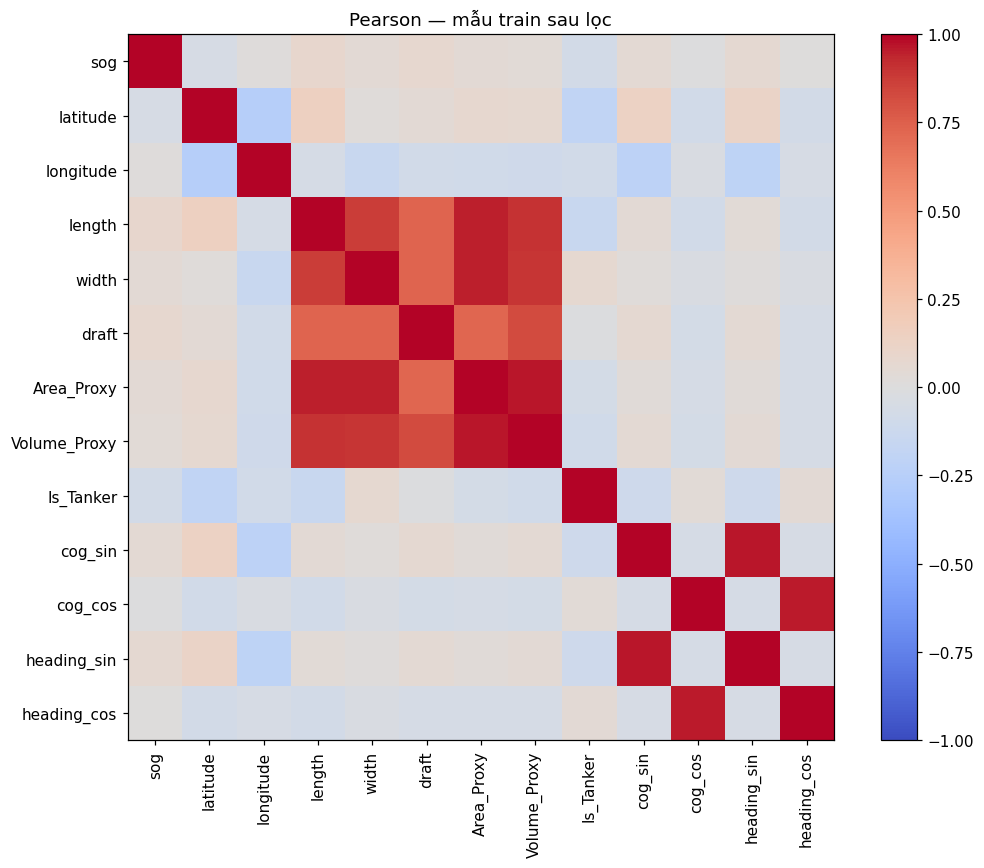

In [11]:
train=prepare_body(train); valid=prepare_body(valid)
for d in [train,valid]:
    d['Area_Proxy']=d.length*d.width; d['Volume_Proxy']=d.Area_Proxy*d.draft
features=['sog','latitude','longitude','length','width','draft','Area_Proxy','Volume_Proxy',
          'Is_Tanker','cog_sin','cog_cos','heading_sin','heading_cos']
if KNOWN_DESTINATION_AT_PREDICTION: features += ['Dist_To_Berth_NM']
features=[c for c in features if train[c].nunique(dropna=True)>1]
assert features, 'Không có biến biến thiên trong train'
correlation=train[features].corr(min_periods=100)
correlation.to_csv(TASK03/'train_pearson.csv',encoding='utf-8-sig')
pairs=[]
for i,a in enumerate(features):
    for b in features[i+1:]:
        r=correlation.loc[a,b]
        if pd.notna(r) and abs(r)>.85:
            pairs.append(dict(feature_1=a,feature_2=b,pearson_r=r,
                              N_pairwise=int(train[[a,b]].notna().all(axis=1).sum())))
pairs=pd.DataFrame(pairs,columns=['feature_1','feature_2','pearson_r','N_pairwise'])
save_table(pairs,TASK03/'high_correlation_pairs.csv'); display(pairs)
reduced=[]; drops=[]
for c in features:
    conflict=next((k for k in reduced if pd.notna(correlation.loc[c,k]) and abs(correlation.loc[c,k])>.85),None)
    if conflict is None: reduced.append(c)
    else: drops.append(dict(removed=c,retained=conflict,r=correlation.loc[c,conflict]))
save_table(pd.DataFrame(drops,columns=['removed','retained','r']),TASK03/'proposed_feature_removals.csv')
fig,ax=plt.subplots(figsize=(10,8)); im=ax.imshow(correlation,vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(len(features))); ax.set_xticklabels(features,rotation=90)
ax.set_yticks(range(len(features))); ax.set_yticklabels(features)
ax.set_title('Pearson — mẫu train sau lọc'); fig.colorbar(im,ax=ax)
save_fig(fig,TASK03/'02_pearson.png')


,model,n_features,best_iteration,MAE_hours,RMSE_hours,bias_hours,overprediction_pct
0,domain_features,13,876,17.322477,24.922772,1.819825,64.547621
1,pearson_reduced,8,1361,17.252900,24.917461,1.893296,64.387203


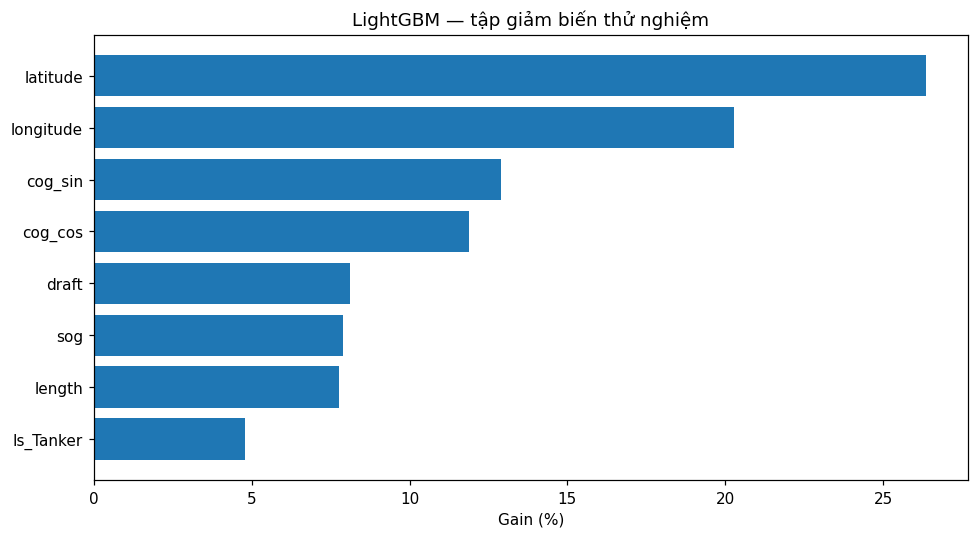

In [12]:
def metrics(y,p):
    e=np.asarray(p)-np.asarray(y)
    return dict(MAE_hours=float(np.mean(abs(e))),RMSE_hours=float(np.sqrt(np.mean(e**2))),
                bias_hours=float(np.mean(e)),overprediction_pct=float(100*np.mean(e>0)))

def fit_lgb(cols,objective='regression'):
    model=lgb.LGBMRegressor(objective=objective,n_estimators=N_ESTIMATORS,learning_rate=.05,
            num_leaves=31,reg_lambda=1.,random_state=SEED,n_jobs=N_JOBS,verbosity=-1,metric='l1')
    model.fit(train[cols],train.Target_Hours,eval_set=[(valid[cols],valid.Target_Hours)],
              eval_metric='l1',callbacks=[lgb.early_stopping(50,first_metric_only=True,verbose=False),lgb.log_evaluation(0)])
    return model

models={}; comparison=[]; group_results=[]
for name,cols in [('domain_features',features),('pearson_reduced',reduced)]:
    model=fit_lgb(cols); pred=model.predict(valid[cols])
    models[name]=(model,cols)
    comparison.append(dict(model=name,n_features=len(cols),best_iteration=model.best_iteration_,**metrics(valid.Target_Hours,pred)))
    gain=model.booster_.feature_importance(importance_type='gain')
    importance=pd.DataFrame(dict(feature=cols,gain=gain,gain_pct=100*gain/max(float(gain.sum()),1e-12))).sort_values('gain',ascending=False)
    save_table(importance,TASK03/('gain_'+name+'.csv'))
    model.booster_.save_model(str(TASK03/('model_'+name+'.txt')))
    groups=pd.cut(valid.Dist_To_Berth_NM,DIST_BINS,labels=DIST_LABELS,include_lowest=True)
    for group in DIST_LABELS:
        take=(groups==group).to_numpy()
        if take.any(): group_results.append(dict(model=name,distance_group=group,N=int(take.sum()),**metrics(valid.Target_Hours.to_numpy()[take],pred[take])))
comparison=pd.DataFrame(comparison); save_table(comparison,TASK03/'feature_selection_validation.csv')
save_table(pd.DataFrame(group_results),TASK03/'validation_by_distance.csv'); display(comparison)
importance=pd.read_csv(TASK03/'gain_pearson_reduced.csv').sort_values('gain_pct')
fig,ax=plt.subplots(figsize=(9,5)); ax.barh(importance.feature,importance.gain_pct)
ax.set_xlabel('Gain (%)'); ax.set_title('LightGBM — tập giảm biến thử nghiệm')
save_fig(fig,TASK03/'03_gain.png')


## B3. Asymmetric loss đúng yêu cầu nghiệp vụ
Đặt e=ŷ−y. Phạt dự báo sớm (e<0) với trọng số 1+α, còn lại 1. Gradient=2we, Hessian=2w (quy ước nhánh tại 0). Thử α=0; 0,5; 1; 1,5. Cấu hình α=1,5 có trọng số phạt sớm 2,5 lần. Đánh giá mọi cấu hình bằng cùng chi phí: mean((2,5 nếu e<0, còn lại 1) × e²), đơn vị giờ². Early stopping dùng MAE; kết quả chỉ là thăm dò validation, không phải test Q4.


In [13]:
asym_table=pd.DataFrame()
if RUN_ASYMMETRIC_EXPERIMENT:
    rows=[]
    def make_early_objective(alpha):
        def early_objective(y_true,y_pred):
            error=y_pred-y_true
            weight=np.where(error<0,1+alpha,1.)
            return 2*weight*error,2*weight
        return early_objective
    for alpha in [0.,.5,1.,1.5]:
        model=fit_lgb(reduced,make_early_objective(alpha))
        pred=model.predict(valid[reduced]); error=pred-valid.Target_Hours.to_numpy()
        rows.append(dict(alpha=alpha,early_weight=1+alpha,best_iteration=model.best_iteration_,
                         **metrics(valid.Target_Hours,pred),
                         underprediction_pct=float(100*np.mean(error<0)),
                         early_cost_weight_2_5=float(np.mean(np.where(error<0,2.5,1.)*error**2))))
        model.booster_.save_model(str(TASK03/f'model_early_alpha_{alpha:g}.txt'))
    asym_table=pd.DataFrame(rows)
    save_table(asym_table,TASK03/'asymmetric_loss_validation.csv'); display(asym_table)
else:
    (TASK03/'asymmetric_loss_validation.csv').unlink(missing_ok=True)
    print('Không chạy loss: chỉ mô tả đề xuất, không có kết quả kiểm chứng.')


,alpha,early_weight,best_iteration,MAE_hours,RMSE_hours,bias_hours,overprediction_pct,underprediction_pct,early_cost_weight_2_5
0,0.0,1.0,1143,17.277068,24.928490,1.844137,64.708039,35.291961,1181.240607
1,0.5,1.5,34,20.600744,29.129923,-2.696370,61.004675,38.995325,1831.791428
2,1.0,2.0,28,21.002374,29.880277,-3.905353,58.919241,41.080759,1956.218381
3,1.5,2.5,26,21.232303,30.165572,-4.027299,58.593822,41.406178,1991.681775


# C. Xuất kết quả và bàn giao
- **RAW2 / Mục 5.4:** SOG, loại tàu, trạng thái, bảng audit. Đỉnh SOG=0 không tự chứng minh lỗi sensor.
- **RAW2 / Mục 6.1:** mô tả nguồn gốc hai lượt, không ghi là notebook đã tái chạy.
- **RAW2 / Mục 6.2:** waterfall trên mẫu, nêu thiếu dedup toàn cục và atd_prev.
- **RAW2 / Mục 6.3:** Bảng 6.1 và tỷ lệ sử dụng từng cấp; 100% coverage không là 100% chính xác.
- **RAW2 / Mục 6.4:** công thức và định nghĩa các đặc trưng.
- **Task 03 / Mục 6.5:** thống kê target, phân nhóm cự ly, giải thích loss.
- **Task 03 / Mục 6.6:** Pearson, Gain, so sánh validation, lý do không PCA.
- RAW2 kế thừa kết quả 6.5–6.6 từ Task 03, không viết hai kết luận mâu thuẫn.

Không lấy số dòng trên mẫu nhân lên để gọi là số dòng sạch đo chính xác. Không ghi MAE mẫu là kết quả Q4 hoặc kết quả toàn bộ dữ liệu.


# C1. Đối chiếu số liệu cũ và tự tạo nội dung Docs
Bảng xác minh phân biệt: đo lại trên đúng raw, đo được nhưng khác quần thể/pipeline, chỉ là metadata đầu vào, hoặc không xác minh được. Không dùng việc một con số tình cờ bằng nhau để xác nhận toàn bộ pipeline.
Bản nháp 6.5–6.6 chỉ dùng output lần này. Đọc phần phạm vi và vị trí hình trước khi dán Docs; mục 6.1–6.4 phải được viết lại theo quy trình mới, không chỉ đổi tiêu đề.


In [ ]:
audit_map=audit.set_index('metric')['count'].to_dict()
checks=[]
def check(metric,old,new,status,note): checks.append(dict(metric=metric,old_reference=old,new_value=new,status=status,note=note))
check('Raw rows',320776922,int(audit_map['N_raw']),'MEASURED_RAW' if MAX_BATCHES is None else 'PARTIAL_SCAN','Đếm scan; không suy rộng từ mẫu')
for c,old in [('length',.353),('width',.916),('draft',.505)]:
    pct=100*audit_map[c+'_nonfinite']/audit_map['N_raw']
    check(c+' missing pct',old,pct,'DIFFERENT_POPULATION','Số cũ trên tập sạch; số mới trên raw; không so như cùng quần thể')
if full_results:
    for metric,old,key in [('Clean rows (old PDF)',80782630,'filtered_rows_no_dedup_no_atd'),
                           ('Clean rows (raw guide)',80660588,'filtered_rows_no_dedup_no_atd'),
                           ('Clean vessels',11275,'filtered_unique_mmsi'),
                           ('Catalog events',102050,'assigned_unique_mmsi_trip'),
                           ('Distance target Pearson',.7629,'filtered_distance_target_pearson'),
                           ('Row groups',365,'metadata_row_groups')]:
        check(metric,old,full_results[key],'NOT_SAME_PIPELINE',
              'Không có atd_prev/dedup/catalog gốc; số đếm mới có định nghĩa trong full_summary.json')
for label,value in [('Original pipeline peak RAM <2GB',2),('Original disk ~3.7GiB',3.7),
                    ('Original catalog vessels',11632),('Original unique ports',6320),
                    ('Original occupied spatial cells',248485),('Original max spatial cell count',150852),
                    ('Original restored draft pct',72.5),('Original Ridge Q4 MAE',15.71)]:
    check(label,value,None,'NOT_VERIFIABLE_FROM_CURRENT_RUN','Cần đầu vào/log/mã pipeline gốc tương ứng; không giữ như kết quả mới')
target_measured=descriptive.set_index('variable').loc['Target_Hours']
for label,old,new in [('Target mean old clean',38.69,float(target_measured.Mean)),
                      ('Target median old clean',25.59,float(target_measured.Median_est)),
                      ('Target Q1 old clean',9.31,float(target_measured.Q1_est)),
                      ('Target Q3 old clean',56.20,float(target_measured.Q3_est))]:
    check(label,old,new,'DIFFERENT_POPULATION','Số cũ trên clean; số mới raw. Phân vị mới là ước lượng mẫu.')
if full_results:
    available=pd.read_csv(AUDIT/'vessel_body_availability.csv').set_index('variable')
    for c,old in [('length',87),('width',244),('draft',25)]:
        check(c+' vessels never valid',old,int(available.loc[c,'vessels_never_valid']),
              'DIFFERENT_POPULATION','Số mới đo trên raw theo định nghĩa mới; không mặc định là cùng đội tàu cũ')
check('Raw duplicate excess',1134051,duplicate_result.get('duplicate_excess'),duplicate_result['status'],duplicate_result['definition'])
check('Original mask vessels',11006,len(vessel_body),'DIFFERENT_POPULATION','Thử nghiệm mới dùng tàu đủ kích thước trong mẫu')
check('Old mask MAPE', 'Bảng 6.1 cũ', 'Xem table_6_1_ship_mask_20_repeats.csv','NEW_EXPERIMENT',
      'Không thay số mới vào bảng cũ mà giữ nguyên nguồn/cách thực nghiệm cũ')
verification=pd.DataFrame(checks);save_table(verification,AUDIT/'old_numbers_verification.csv');display(verification)

def fmt(v,d=4):
    if isinstance(v,(int,np.integer)):return f'{v:,}'
    if isinstance(v,(float,np.floating)):return f'{v:,.{d}f}' if np.isfinite(v) else 'NA'
    return str(v)
def mtable(df):
    cols=list(df.columns)
    lines=['| '+' | '.join(map(str,cols))+' |','| '+' | '.join(['---']*len(cols))+' |']
    for row in df.itertuples(index=False,name=None): lines.append('| '+' | '.join(fmt(v) for v in row)+' |')
    return '\n'.join(lines)
raw_target=descriptive.loc[descriptive.variable=='Target_Hours'].iloc[0]
a=comparison.set_index('model').loc['domain_features'];b=comparison.set_index('model').loc['pearson_reduced']
delta=float(b.MAE_hours-a.MAE_hours)
selection=('Tập giảm biến có MAE thấp hơn trong lần chạy này; cần kiểm chứng thêm trước khi chốt cấu hình.' if delta<0 else
           'Giảm biến không cải thiện MAE trong lần chạy này; giữ tập đầy đủ làm phương án tham chiếu, tập giảm biến là lựa chọn gọn hơn chưa có bằng chứng tiết kiệm thời gian.')
cap_note=('Có mô hình đạt gần trần số vòng; chưa khẳng định đã hội tụ tối ưu.' if comparison.best_iteration.max()>=.95*N_ESTIMATORS else
          'Early stopping chỉ lựa chọn số vòng theo validation, không chứng minh tối ưu toàn cục.')
raw_table=descriptive.loc[descriptive.variable=='Target_Hours',['N','Mean','Std','Min','Max','N_sample','Q1_est','Median_est','Q3_est','Skew_est']].T.reset_index()
raw_table.columns=['Chỉ số','Giá trị']
loss_text='Chưa chạy thí nghiệm loss; chỉ trình bày phương pháp đề xuất.'
if len(asym_table):
    target_row=asym_table.loc[asym_table.alpha==1.5].iloc[0];base_row=asym_table.loc[asym_table.alpha==0].iloc[0]
    loss_text=(mtable(asym_table)+'\n\n'+
       f'Cấu hình phạt sớm 2,5 lần có MAE {target_row.MAE_hours:.4f} giờ, RMSE {target_row.RMSE_hours:.4f} giờ. '
       f'Chênh lệch MAE so với α=0: {target_row.MAE_hours-base_row.MAE_hours:+.4f} giờ. '
       f'Chênh lệch chi phí phạt sớm chung: {target_row.early_cost_weight_2_5-base_row.early_cost_weight_2_5:+.4f} giờ². '
       'Không mặc định loss bất đối xứng tốt hơn về mọi độ đo. Các cấu hình này thuộc thực nghiệm custom objective riêng, không thay hàng baseline trong bảng lựa chọn đặc trưng.')
removed=pd.DataFrame(drops,columns=['removed','retained','r'])
gain_current=pd.read_csv(TASK03/'gain_pearson_reduced.csv')
gain_all=pd.read_csv(TASK03/'gain_domain_features.csv')
content=f"""# 6.5. Xử lý phân phối mất cân bằng của giá trị mục tiêu

## 6.5.1. Phạm vi và phân phối target
Thống kê đầu vào: {SCOPE}, {int(audit_map['N_raw']):,} bản ghi raw labeled. Đây là bài toán hồi quy liên tục, không phải mất cân bằng lớp. Có {int(raw_target.N):,} target hữu hạn. Mean/Std/Min/Max tính trên toàn bộ phần raw đã quét; phân vị và skewness ước lượng từ {int(raw_target.N_sample):,} target hữu hạn trong mẫu lấy ngẫu nhiên.

{mtable(raw_table)}

[Chèn TASK03/01_target_distribution.png]
Hình 6.1. Target raw: bên trái log(1+Target_Hours) trên mẫu; bên phải phần raw trong [0,168] giờ. Log chỉ dùng hiển thị; target huấn luyện vẫn theo giờ. Hình bên phải chưa qua toàn bộ bộ lọc.

Mean={raw_target.Mean:.2f} giờ, median ước lượng={raw_target.Median_est:.2f} giờ, skewness ước lượng={raw_target.Skew_est:.4f}. Phân phối có đuôi phải dài. Cửa sổ (0,168] là phạm vi nghiệp vụ, không phải toàn bộ raw vốn đã có nhãn trong khoảng này. Không oversample/undersample theo target để cân bằng nhân tạo; lấy mẫu đều phục vụ giới hạn tính toán.

## 6.5.2. Phân tầng theo cự ly
Bảng sau tính trên {len(work):,} bản ghi mẫu sau lọc, gồm cả các giai đoạn trong năm; đây là EDA, không dùng Q4 để chọn mô hình.

{mtable(distance_summary)}

Khoảng cách/target>=3 là bộ lọc dùng nhãn, nên quan hệ trong bảng bị điều kiện hóa bởi cách chọn mẫu, không chứng minh quan hệ tự nhiên trên raw. Cự ly được tính từ bến gán nhãn; sử dụng cho phân nhóm ngoại tuyến. {'Mô hình đưa cự ly vào X theo giả định bến đích biết trước.' if KNOWN_DESTINATION_AT_PREDICTION else 'Mô hình không đưa cự ly tới bến vào X.'}

Đánh giá trên {len(valid):,} dòng validation:

{mtable(pd.DataFrame(group_results))}

Bias là mean(ŷ−y): dương là dự báo thời gian còn lại lớn hơn thực tế, âm là nhỏ hơn. Không đánh giá chất lượng chỉ bằng chỉ số tổng; kết quả giới hạn trong quần thể đã lọc, chưa là Q4 hoặc vận hành toàn bộ raw.

## 6.5.3. Asymmetric loss theo nghiệp vụ phạt sớm
Với e=ŷ−y, L=w(e)e², w=1+α nếu e<0 và w=1 nếu e>=0. Gradient=2we; Hessian=2w theo quy ước nhánh tại 0. α=1,5 ứng với phạt dự báo sớm 2,5 lần. Loss thay đổi chi phí tối ưu, không làm target hết lệch phải. Mọi cấu hình được đối chiếu cùng chi phí đánh giá phạt sớm 2,5 lần, đơn vị giờ²; early stopping dùng MAE.

{loss_text}

# 6.6. Lựa chọn đặc trưng và lý do không áp dụng PCA

## 6.6.1. Thiết kế thực nghiệm
Đầu vào duy nhất là raw labeled. Train tháng 1–6: {len(train):,} dòng mẫu sau lọc; validation tháng 7–9: {len(valid):,} dòng. Nhãn phải hoàn tất trước cuối mỗi giai đoạn; loại giao nhau theo (mmsi,trip_id). Q4 không dùng để điều chỉnh hoặc đánh giá cuối cùng ở đây. Chỉ một lần chia; chưa có khoảng tin cậy qua nhiều lần thực nghiệm.

Tập biến ban đầu: {', '.join(features)}.
Target_Hours/ata_time không vào X; mã tàu/chuyến chỉ quản lý và chia tập. LightGBM dùng NaN trực tiếp; kiểm chứng imputation là thực nghiệm riêng. Không tuyên bố đây là mô hình được huấn luyện trên toàn bộ dữ liệu đã điền khuyết.

## 6.6.2. Pearson và đề xuất giảm biến
[Chèn TASK03/02_pearson.png]
Hình 6.2. Ma trận Pearson trên mẫu train sau lọc. Mỗi cặp dùng các dòng đủ hai biến, xem N_pairwise trong high_correlation_pairs.csv.

Với ngưỡng |r|>0,85 và thứ tự ưu tiên trong notebook:

{mtable(removed)}

Tập giảm biến: {', '.join(reduced)}. Tương quan không có nghĩa hai biến hoàn toàn thay thế nhau. Heading và COG vẫn khác ý nghĩa vật lý. Đây là đề xuất thử nghiệm, không tự động là cấu hình cuối.

## 6.6.3. Đối chiếu validation
{mtable(comparison)}

Chênh lệch MAE (giảm biến trừ đầy đủ): {delta:+.4f} giờ. {selection} {cap_note}
Chưa đo tốc độ/độ trễ nên không suy ra mức tiết kiệm tài nguyên từ số biến.

## 6.6.4. Gain
[Chèn TASK03/03_gain.png]
Hình 6.3. Gain của phương án giảm biến thử nghiệm.

{mtable(gain_current[['feature','gain_pct']])}

Đối chiếu tập đầy đủ:

{mtable(gain_all[['feature','gain_pct']])}

Gain là mức giảm objective tích lũy trong các phép chia cây, không phải tỷ lệ phương sai giải thích hoặc quan hệ nhân quả. Gain có thể phân bổ lại khi bỏ biến tương quan; không loại thêm biến chỉ vì Gain thấp. Hình tập giảm biến không khẳng định tập này được lựa chọn cuối cùng.

## 6.6.5. Không áp dụng PCA
Nhóm giữ biểu diễn trực tiếp của vị trí, vận tốc, kích thước và hướng để hỗ trợ diễn giải. PCA tối ưu phương sai đầu vào, không trực tiếp tối ưu target. Với số biến nhỏ, ưu tiên tri thức miền, Pearson, Gain và validation. Không khẳng định PCA hoàn toàn không thể giải thích hoặc luôn làm giảm hiệu năng.

## Giới hạn xác minh
Không có atd_prev/catalog gốc; waterfall chưa dedup toàn cục. Đếm trùng lặp tùy chọn chỉ kiểm kê, không thay đổi tập huấn luyện. Kết quả mẫu không thay thế số liệu sạch toàn bộ hoặc baseline Q4 cũ. Xem AUDIT/old_numbers_verification.csv trước khi giữ số liệu trong Docs.
"""
(REPORTS/'Muc_6_5_6_6.md').write_text(content,encoding='utf-8')
(REPORTS/'Huong_dan_sua_Docs.md').write_text("""# Những phần cũ phải sửa
- 6.1: mô tả đọc raw theo batch của notebook này. Pass 1/Pass 2 chỉ là nguồn gốc theo tài liệu, không phải thao tác đã tái chạy. Bỏ số tàu/chuyến/RAM/đĩa cũ chưa kiểm chứng.
- 6.2: công thức nhãn và cửa sổ (0,168] là quy tắc. Bỏ tỷ lệ tích lũy 24/48/72 giờ từ tập sạch cũ. Dùng raw_audit.
- Bộ lọc: dùng full_filter_waterfall cho toàn raw với chú thích thiếu atd_prev và dedup. Không gọi số dòng cuối là tái tạo đúng pipeline cũ.
- Không gọi target sau lọc status là Steaming Time thuần túy: nhãn ATA-t vẫn có thể bao gồm chờ trong tương lai.
- 6.3: thay số thiếu bằng raw_audit; thay bảng mask cũ bằng kết quả thí nghiệm mới và đúng thiết kế. Bảng che theo thời gian khác bảng che theo tàu 20 lần. Không nói đã chạy 11.006 tàu nếu số mới khác.
- 6.4: proxy chỉ đại diện kích thước; khoảng cách đại vòng xấp xỉ; góc không hợp lệ thành NaN, không phải (0,0)+flag. Model thử nghiệm dùng NaN trực tiếp.
- 6.5–6.6: chèn Muc_6_5_6_6.md, đặt ba hình TASK03 vào vị trí ghi chú.
- 7.1: phân biệt cấu hình 21 biến dự kiến/cũ với cấu hình thử nghiệm mới; không tự thay tất cả thành số biến giảm.
- 7.5: đồng bộ e=ŷ-y; phạt e<0 gấp 2,5 khi alpha=1,5. Bỏ kết quả V1 phạt ngược. Không chọn alpha từ Q4.
- 8: báo cáo thử nghiệm train Jan-Jun/validation Jul-Sep riêng với kế hoạch train Jan-Sep/test Q4. Không gọi validation hiện tại là test Q4.
""",encoding='utf-8')
print('Đã tạo bản nháp:',REPORTS/'Muc_6_5_6_6.md')


In [15]:
manifest=dict(input=str(raw_path),scope=SCOPE,sample_rows=len(sample),filtered_sample_rows=len(work),
              train_rows=len(train),validation_rows=len(valid),known_destination=KNOWN_DESTINATION_AT_PREDICTION,
              features=features,reduced_features=reduced,scan_config=scan_config,
              versions=dict(python=platform.python_version(),pandas=pd.__version__,numpy=np.__version__,lightgbm=lgb.__version__),
              limitations=['No global dedup','No atd_prev','No catalog reconstruction','No final Q4 evaluation',
                           'Target-based cohort filtering: offline research only','Imputation experiment separate from model experiment'])
(OUT/'run_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
readme=f"""KẾT QUẢ TASK03 & RAW2
Phạm vi: {SCOPE}
Input: {raw_path}
Mẫu raw: {len(sample):,}; mẫu sau lọc: {len(work):,}
Train: {len(train):,}; validation: {len(valid):,}; không đánh giá Q4.
RAW2: Mục 5.4, 6.1–6.4. TASK03: Mục 6.5–6.6.
Moments/counts trên raw đã quét; quantiles/skewness trên mẫu.
Không tái tạo đầy đủ pipeline gốc: thiếu atd_prev, dedup toàn cục và catalog nguồn.
Đọc markdown notebook để diễn giải bảng đúng phạm vi.
"""
(OUT/'README_results.txt').write_text(readme,encoding='utf-8')
zip_path=OUT.parent/'task03_raw02_v2_results.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for path in sorted(OUT.rglob('*')):
        if path.is_file() and path.suffix!='.parquet' and 'duckdb_tmp' not in path.parts:
            z.write(path,path.relative_to(OUT))
print('Đã lưu kết quả:',OUT)
print('ZIP không chứa mẫu parquet để gọn; mẫu vẫn nằm trong COMMON.')
display(FileLink(str(zip_path)))


Đã lưu kết quả: /kaggle/working/task03_raw02_v2
ZIP không chứa mẫu parquet để gọn; mẫu vẫn nằm trong COMMON.


/kaggle/working/task03_raw02_v2_results.zip